<a href="https://colab.research.google.com/github/remifakunle59-design/Forest-Carbon-Analysis/blob/main/Model_ready_netcdf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model-ready Earth observation data: Landsat NDVI cube as NetCDF (Xarray + Dask)

**Question:** How can cloud-hosted Landsat data be turned into a documented, reusable, model-ready gridded dataset?

**Approach**
1. Read Landsat Collection 2 Level-2 from Microsoft Planetary Computer (STAC) for two dry seasons (2013 and 2020) over southeastern Osun State, Nigeria.
2. Mask clouds, compute a median NDVI composite and the number of clear observations per pixel.
3. Combine the years into one Xarray dataset with named dimensions (year, y, x), units and metadata.
4. Save it as a compressed NetCDF file, reopen it lazily with Dask chunks and check that nothing was lost.

**Limitations (stated up front)**
- Two years only, from two different sensors (Landsat 7 in 2013, Landsat 8 in 2020): the NDVI difference is a demonstration, not a measured vegetation change.
- 90 m resolution to keep the notebook fast.
- This prepares an input dataset. It does not estimate carbon stocks or fluxes.

In [1]:
!pip install -q pystac-client planetary-computer odc-stac netCDF4

In [2]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import planetary_computer as pc
from pystac_client import Client
from odc.stac import load

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)
bbox = [4.25, 7.0, 5.0, 7.75]     # west, south, east, north (degrees)
CRS, RES = "EPSG:32631", 90       # UTM zone 31N, 90 m pixels
windows = {
    2013: (["landsat-7"], "2012-12-01/2013-04-30"),
    2020: (["landsat-8"], "2019-12-01/2020-04-30"),
}
MAX_CLOUD = 60

## 1. NDVI composite and clear-observation count for each year

Besides NDVI, each pixel also gets the number of clear (cloud-free) observations behind it. A model can use this as a quality layer: pixels based on one observation are less reliable than pixels based on six.

In [3]:
def composite(year, n=6):
    plats, dt = windows[year]
    items = sorted(
        catalog.search(collections=["landsat-c2-l2"], bbox=bbox, datetime=dt,
                       query={"platform": {"in": plats},
                              "eo:cloud_cover": {"lt": MAX_CLOUD}}).items(),
        key=lambda i: i.properties["eo:cloud_cover"])[:n]
    print(year, "scenes used:", len(items),
          [(i.properties["platform"], i.datetime.strftime("%Y-%m-%d")) for i in items])
    ds = load(items, bands=["red", "nir08", "qa_pixel"], bbox=bbox,
              crs=CRS, resolution=RES, chunks={})
    clear = (ds.qa_pixel & 0b11111) == 0
    red = (ds.red * 0.0000275 - 0.2).where(clear)       # surface reflectance
    nir = (ds.nir08 * 0.0000275 - 0.2).where(clear)
    ndvi = ((nir - red) / (nir + red)).median("time", skipna=True)
    n_clear = clear.sum("time")
    return ndvi.astype("float32").compute(), n_clear.astype("int16").compute()

parts = {y: composite(y) for y in windows}

2013 scenes used: 6 [('landsat-7', '2013-01-01'), ('landsat-7', '2012-12-23'), ('landsat-7', '2012-12-23'), ('landsat-7', '2013-01-08'), ('landsat-7', '2012-12-07'), ('landsat-7', '2012-12-16')]


/usr/local/lib/python3.13/dist-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/usr/local/lib/python3.13/dist-packages/rasterio/warp.py:390: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dest = _reproject(


2020 scenes used: 6 [('landsat-8', '2019-12-28'), ('landsat-8', '2020-02-05'), ('landsat-8', '2020-02-21'), ('landsat-8', '2020-02-14'), ('landsat-8', '2020-01-20'), ('landsat-8', '2019-12-19')]


## 2. One dataset with named dimensions and metadata

A model-ready dataset should explain itself: dimension names, units, coordinate system, data source and processing steps are stored inside the file.

In [4]:
years = sorted(parts)
ndvi = xr.concat([parts[y][0] for y in years], dim=xr.DataArray(years, dims="year", name="year"))
n_clear = xr.concat([parts[y][1] for y in years], dim=xr.DataArray(years, dims="year", name="year"))

cube = xr.Dataset({"ndvi": ndvi, "n_clear_obs": n_clear})
cube["ndvi"].attrs = {"long_name": "Median NDVI of clear pixels, dry-season composite",
                      "units": "1", "valid_range": [-1.0, 1.0]}
cube["n_clear_obs"].attrs = {"long_name": "Number of clear observations in the composite",
                             "units": "1"}
cube.attrs = {
    "title": "Landsat NDVI cube, southeastern Osun State, Nigeria",
    "source": "Landsat Collection 2 Level-2 surface reflectance via Microsoft Planetary Computer",
    "processing": "QA_PIXEL mask (bits 0-4 clear); scale 0.0000275, offset -0.2; median over up to 6 scenes",
    "crs": CRS, "resolution_m": RES,
    "caveat": "2013 = Landsat 7, 2020 = Landsat 8: absolute NDVI is not strictly comparable across sensors",
}
print(cube)

<xarray.Dataset> Size: 10MB
Dimensions:      (y: 926, x: 924, year: 2)
Coordinates:
  * y            (y) float64 7kB 8.572e+05 8.571e+05 ... 7.74e+05 7.74e+05
  * x            (x) float64 7kB 6.379e+05 6.38e+05 ... 7.209e+05 7.209e+05
  * year         (year) int64 16B 2013 2020
    spatial_ref  int32 4B 32631
Data variables:
    ndvi         (year, y, x) float32 7MB 0.0 0.0 0.0 ... 0.5689 0.5894 0.5979
    n_clear_obs  (year, y, x) int16 3MB 6 6 6 6 6 6 6 6 6 ... 2 2 2 2 2 2 2 2 2
Attributes:
    title:         Landsat NDVI cube, southeastern Osun State, Nigeria
    source:        Landsat Collection 2 Level-2 surface reflectance via Micro...
    processing:    QA_PIXEL mask (bits 0-4 clear); scale 0.0000275, offset -0...
    crs:           EPSG:32631
    resolution_m:  90
    caveat:        2013 = Landsat 7, 2020 = Landsat 8: absolute NDVI is not s...


## 3. Save as NetCDF and read it back

The file is compressed and can be reopened lazily: Xarray only reads the chunks that a calculation needs, and Dask can process chunks in parallel.

In [5]:
path = "osun_ndvi_cube.nc"
cube.to_netcdf(path, encoding={v: {"zlib": True, "complevel": 4} for v in cube.data_vars})

import os
print("Saved", path, "-", round(os.path.getsize(path) / 1e6, 1), "MB")

back = xr.open_dataset(path, chunks={"year": 1, "y": 256, "x": 256})   # lazy, Dask-backed
print("Chunks of ndvi:", back.ndvi.chunks)

# Round-trip check: values must be identical after saving and reloading
xr.testing.assert_identical(cube.ndvi.load(), back.ndvi.load())
print("Round trip OK: reloaded NDVI matches the original")

Saved osun_ndvi_cube.nc - 4.4 MB
Chunks of ndvi: ((1, 1), (256, 256, 256, 158), (256, 256, 256, 156))
Round trip OK: reloaded NDVI matches the original


## 4. Using the cube

Mean NDVI per year and a difference map, both computed on the reloaded Dask arrays.

year
2013    0.54
2020    0.47
Name: ndvi, dtype: float32


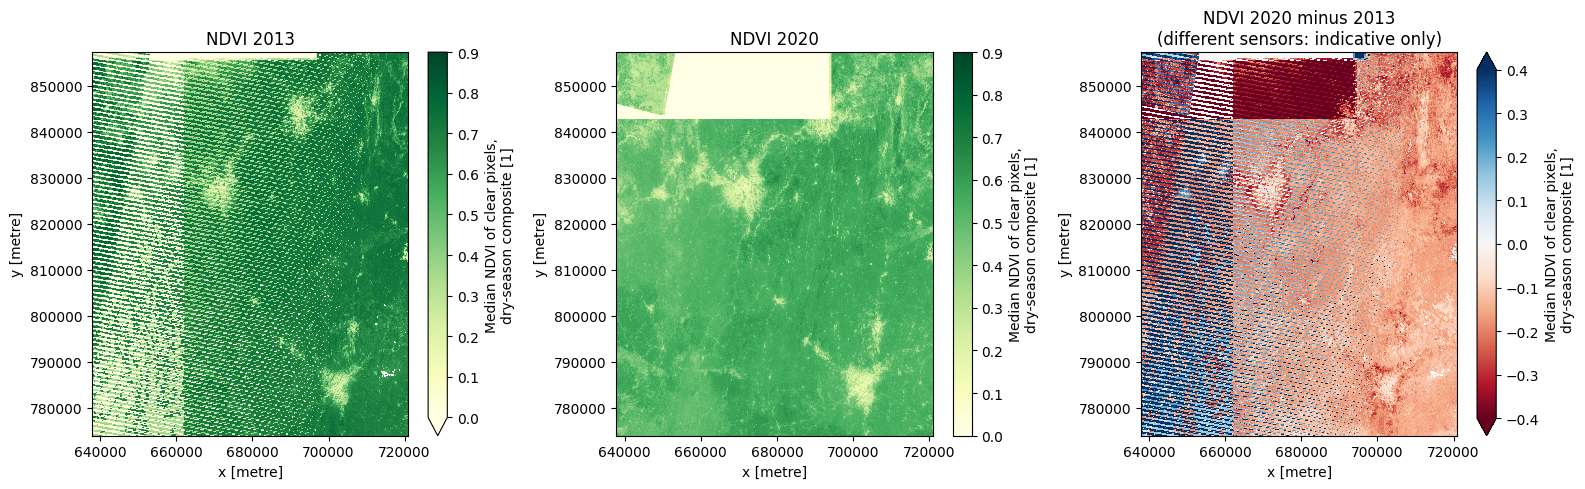

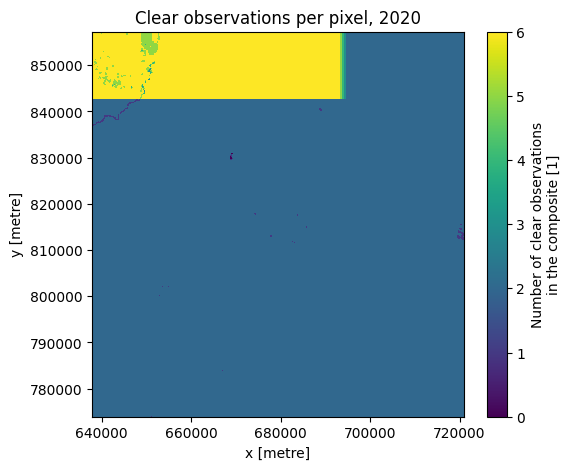

In [6]:
print(back.ndvi.mean(("x", "y")).compute().to_series().round(2))

diff = (back.ndvi.sel(year=2020) - back.ndvi.sel(year=2013)).compute()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, y in zip(axes[:2], years):
    back.ndvi.sel(year=y).plot(ax=ax, vmin=0, vmax=0.9, cmap="YlGn")
    ax.set_title(f"NDVI {y}")
diff.plot(ax=axes[2], cmap="RdBu", vmin=-0.4, vmax=0.4)
axes[2].set_title("NDVI 2020 minus 2013\n(different sensors: indicative only)")
plt.tight_layout()
plt.show()

back.n_clear_obs.sel(year=2020).plot(figsize=(6, 5), cmap="viridis")
plt.title("Clear observations per pixel, 2020")
plt.show()

## How a carbon or flux model could use this

A gridded cube like this can be an input layer for land-surface or carbon models, next to biomass, forest-age or disturbance maps. The metadata, the quality layer and the common grid are what make it reusable.

**What it is not.** NDVI is a greenness index. It is not biomass, a carbon stock or a carbon flux. Turning it into carbon estimates needs calibration with field data (as in my MSc thesis) and a method that propagates uncertainty.

## Limitations and next steps

- Two sensors and two years only; a consistent long time series needs sensor harmonisation or a single-sensor record.
- Add a wet-season composite and more years, then store the full time series as a chunked NetCDF or Zarr store.
- Clip to the official study-area boundary (see notebook 02).
- Add the 2020 land-cover classification and the thesis carbon-stock values as further variables.

Data: Landsat Collection 2 Level-2 via Microsoft Planetary Computer.